# Alaska boreal 2022: high vs. low detections

VIFDAHL run `AK_boreal_2022`: SNPP, local solar dates 2022-04-26 to 2022-09-25. There is one AOI
(`Boreal_AK_and_adjacent_CA`). As a first split, detections are grouped by the 141°W meridian
(the Alaska–Yukon border north of 60.3°N). This split is a placeholder until land cover or
ecoregion data are added.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from vifdahl.analysis import load_points, plot_date_scatter, plot_histograms, plot_tb_scatter

GPKG_ROOT = Path("../output/AK_boreal_2022/gpkg")
FIG_DIR = Path("../output/AK_boreal_2022/figures")
BORDER_LON = -141.0
FIG_DIR.mkdir(exist_ok=True)

In [2]:
points = load_points(GPKG_ROOT)
points["region"] = np.where(points["LON"] < BORDER_LON, "Alaska (W of 141°W)",
                            "Canada (E of 141°W)")
print(f"{len(points):,} detections; platforms: {', '.join(points['Platform'].unique())}")

124,155 detections; platforms: NPP


## Detection counts

In [3]:
pd.crosstab(points["region"], points["Type"], margins=True)

Type,A,H,L,All
region,,,,
Alaska (W of 141°W),6993,57510,32695,97198
Canada (E of 141°W),970,10081,15906,26957
All,7963,67591,48601,124155


In [4]:
pd.crosstab([points["region"], points["sun"]], points["Type"])

Type                             A      H      L
region              sun                         
Alaska (W of 141°W) sun down   182   6278   7446
                    sun up    6811  51232  25249
Canada (E of 141°W) sun down    52   2183   6912
                    sun up     918   7898   8994

In [5]:
points.loc[points["Type"] != "A"].groupby(["region", "sun", "Type"])[["TB4", "TB5", "ndiff"]] \
    .median().round(3)

TB4      TB5  ndiff
region              sun      Type                         
Alaska (W of 141°W) sun down H     321.627  277.876  0.073
                             L     296.151  278.780  0.033
                    sun up   H     338.826  294.416  0.067
                             L     322.260  304.165  0.035
Canada (E of 141°W) sun down H     321.176  282.382  0.064
                             L     296.584  281.197  0.030
                    sun up   H     338.613  295.230  0.066
                             L     322.195  309.173  0.020

## Histograms: H vs. L

**Sun up / sun down** is decided per pixel from the solar zenith angle (≤ 90° = sun up).
It is not the same as the `Period` column (local solar time 06–18 / 18–06) and not necessarily
the threshold set the algorithm applied. With `daynight = "scene"`, a whole granule is classified
with night thresholds unless every pixel is sunlit. North of ~66°N in June and July, the sun
never sets, so most "night" detections were made in daylight.

The day thresholds produce hard edges in the histograms: H and L require TB4 > 320 K and TB5 > 285 K.

A pixels (saturated or folded TB4) are counted in the tables but left out of all
brightness-temperature plots.

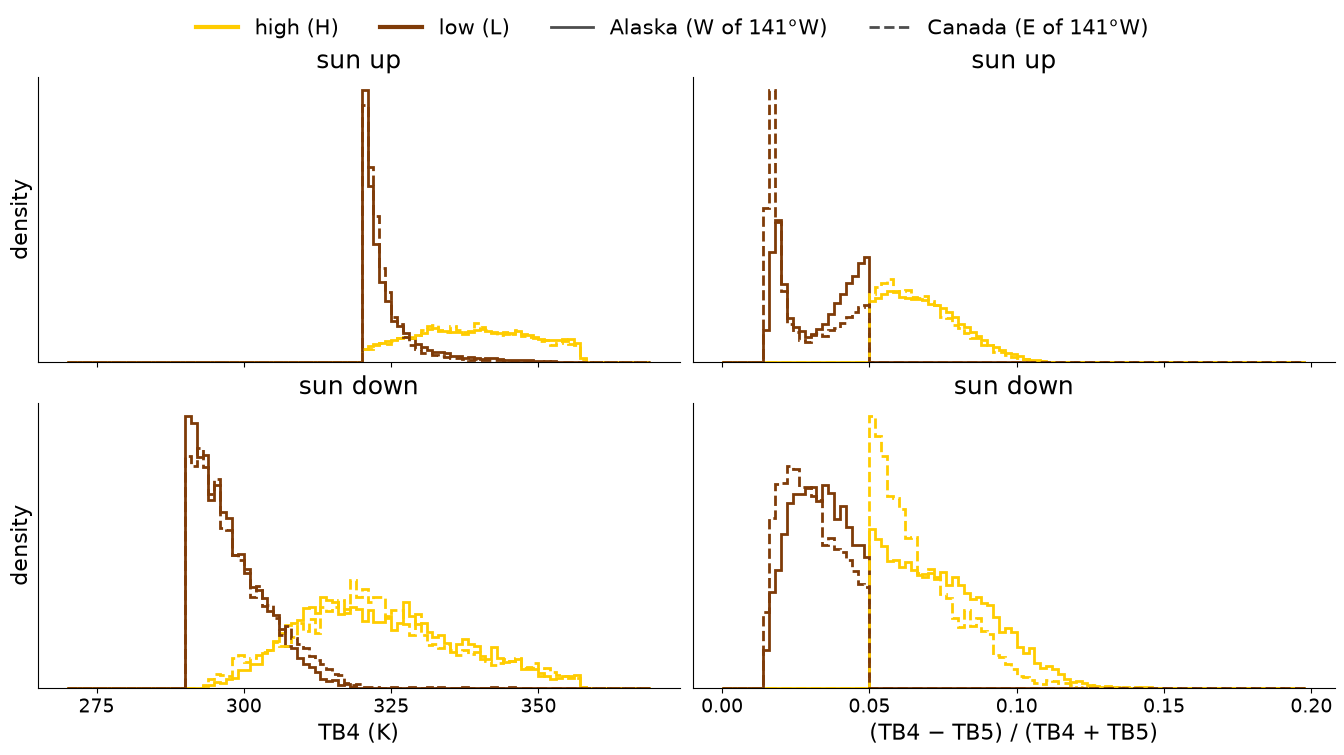

In [6]:
fig = plot_histograms(points, "region")
fig.savefig(FIG_DIR / "hist_region.png", dpi=150)

## TB4 vs. TB5, colored by local date

In [7]:
fig = plot_tb_scatter(points, "region")
fig.savefig(FIG_DIR / "scatter_tb_date.png", dpi=150)

## TB4 over the season

Points are jittered by ±0.4 days within each local date.

In [8]:
fig = plot_date_scatter(points, "region")
fig.savefig(FIG_DIR / "scatter_date_tb4.png", dpi=150)